In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [20]:
df = pd.read_csv('solar_system.csv')
df

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
0,Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
1,Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
2,Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
3,Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
4,Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3
5,Rotation Period (hours),1407.6,-5832.5,23.9,655.7,24.6,9.9,10.7,-17.2,16.1,-153.3
6,Length of Day (hours),4222.6,2802.0,24.0,708.7,24.7,9.9,10.7,17.2,16.1,153.3
7,Distance from Sun (10^6 km),57.9,108.2,149.6,0.384,228.0,778.5,1432.0,2867.0,4515.0,5906.4
8,Perihelion (10^6 km),46.0,107.5,147.1,0.363,206.7,740.6,1357.6,2732.7,4471.1,4436.8
9,Aphelion (10^6 km),69.8,108.9,152.1,0.406,249.3,816.4,1506.5,3001.4,4558.9,7375.9


In [10]:
print(df.shape)
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns.")
print(df.head())
print(df.tail())
print(df.columns.tolist())
print(df.index.tolist())

(20, 11)
The dataset has 20 rows and 11 columns.
                Attribute Mercury  Venus  Earth   Moon   Mars Jupiter  Saturn  \
0          Mass (10^24kg)   0.330   4.87   5.97  0.073  0.642    1898     568   
1           Diameter (km)    4879  12104  12756   3475   6792  142984  120536   
2        Density (kg/m^3)    5429   5243   5514   3340   3934    1326     687   
3         Gravity (m/s^2)     3.7    8.9    9.8    1.6    3.7    23.1     9.0   
4  Escape Velocity (km/s)     4.3   10.4   11.2    2.4    5.0    59.5    35.5   

  Uranus Neptune   Pluto  
0   86.8     102  0.0130  
1  51118   49528    2376  
2   1270    1638    1850  
3    8.7    11.0     0.7  
4   21.3    23.5     1.3  
                  Attribute Mercury Venus Earth Moon  Mars  Jupiter   Saturn  \
15     Mean Temperature (C)     167   464    15  -20   -65     -110     -140   
16  Surface Pressure (bars)       0    92     1    0  0.01  Unknown  Unknown   
17          Number of Moons       0     0     1    0     2    

In [13]:
orbital_period = df.iloc[10, 1:].astype(float)
perihelion = df.iloc[8, 1:].astype(float)
aphelion = df.iloc[9, 1:].astype(float)

In [14]:
semi_major_axis = (perihelion + aphelion) / 2

In [21]:
new_row = pd.Series(semi_major_axis, name='Semi-major axis (AU)')
df = pd.concat([df, new_row.to_frame().T])
df

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
0,Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
1,Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
2,Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
3,Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
4,Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3
5,Rotation Period (hours),1407.6,-5832.5,23.9,655.7,24.6,9.9,10.7,-17.2,16.1,-153.3
6,Length of Day (hours),4222.6,2802.0,24.0,708.7,24.7,9.9,10.7,17.2,16.1,153.3
7,Distance from Sun (10^6 km),57.9,108.2,149.6,0.384,228.0,778.5,1432.0,2867.0,4515.0,5906.4
8,Perihelion (10^6 km),46.0,107.5,147.1,0.363,206.7,740.6,1357.6,2732.7,4471.1,4436.8
9,Aphelion (10^6 km),69.8,108.9,152.1,0.406,249.3,816.4,1506.5,3001.4,4558.9,7375.9


In [22]:
print(df.shape)

(21, 11)


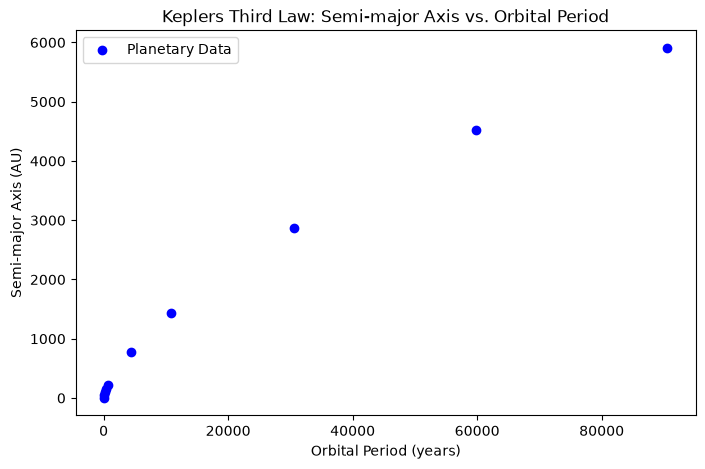

In [23]:
plt.figure(figsize=(8, 5))
plt.scatter(orbital_period, semi_major_axis, color='blue', label='Planetary Data')
plt.xlabel('Orbital Period (years)')
plt.ylabel('Semi-major Axis (AU)')
plt.title('Keplers Third Law: Semi-major Axis vs. Orbital Period')
plt.legend()
plt.show()

--- Fitted Model Parameter ---
Best-fit slope (m): 0.20
Fitted Equation: T = 0.20 * a^1.5
Chi-squared: 371490.35
Reduced Chi-squared: 41276.71


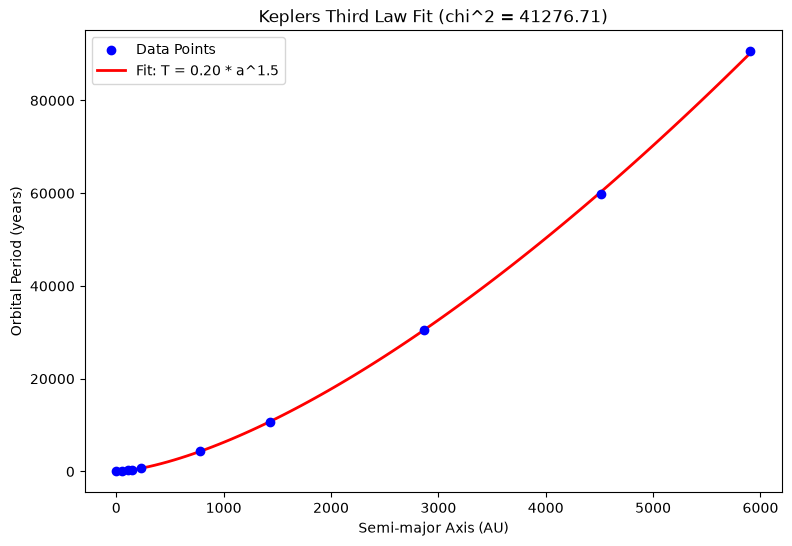

In [24]:
def keplers_third_law(a, m):
    return m * a ** 1.5

popt, pcov = curve_fit(keplers_third_law, semi_major_axis, orbital_period)
best_m = popt[0]


print("--- Fitted Model Parameter ---")
print(f"Best-fit slope (m): {best_m:.2f}")
print(f"Fitted Equation: T = {best_m:.2f} * a^1.5")

y_pred = keplers_third_law(semi_major_axis, best_m)
y_err = 1.0 

dof = len(orbital_period) - 1

chi_squared = np.sum(((orbital_period - y_pred) / y_err) ** 2)
reduced_chi_squared = chi_squared / dof

print(f"Chi-squared: {chi_squared:.2f}")
print(f"Reduced Chi-squared: {reduced_chi_squared:.2f}")


plt.figure(figsize=(9, 6))
plt.scatter(semi_major_axis, orbital_period, color='blue', label='Data Points', zorder=3)
a_fit = np.linspace(min(semi_major_axis), max(semi_major_axis), 100)
t_fit = keplers_third_law(a_fit, best_m)
plt.plot(a_fit, t_fit, color='red', linestyle='-', linewidth=2, label=f'Fit: T = {best_m:.2f} * a^1.5')

plt.xlabel('Semi-major Axis (AU)')
plt.ylabel('Orbital Period (years)')

plt.title(f'Keplers Third Law Fit (chi^2 = {reduced_chi_squared:.2f})')
plt.legend()
plt.show()

In [25]:
df.to_csv('kepler.csv', index=True)